# Copy this notebook into usr/ and adjust to your needs.

In [16]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
### setup ###

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# setup path to python virtual env & code directory
ecf_env_path = '/Users/kszczepaniak/Code/ecf-explorer-env'
lib_ecf_path = ecf_env_path + '/ecf-explorer/src'
sys.path.append(lib_ecf_path)

from utils.postprocess import load_clustering_results
from utils.postprocess import load_features_data
#from plots.plot_clustering_and_ecfs import plot_alignment_selected

workdir_path = '/Users/kszczepaniak/Data/Phage/phage-pp-workdir-ecftest-300'

In [18]:
# load cluster stat data
clustering_results = load_clustering_results(workdir_path, mode='stats')
clustering_results

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711
...,...,...,...,...,...,...,...
21816,reprseq28150,0,6,0.987179,246,0.981707,0.987952
21817,reprseq28150,1,5,0.980762,230,0.974783,0.923695
21818,reprseq17482,0,54,0.930663,194,0.846793,0.989796
21819,reprseq17482,1,19,0.861693,109,0.783679,0.556122


In [19]:
# filter clusters
clustering_results = clustering_results[clustering_results['avg_hits_overlap'] >= 0.0]
clustering_results

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711
...,...,...,...,...,...,...,...
21816,reprseq28150,0,6,0.987179,246,0.981707,0.987952
21817,reprseq28150,1,5,0.980762,230,0.974783,0.923695
21818,reprseq17482,0,54,0.930663,194,0.846793,0.989796
21819,reprseq17482,1,19,0.861693,109,0.783679,0.556122


In [181]:
# load GOs data
features_to_load = ['go.hits.all']

features_data = load_features_data(workdir_path, features_to_load, sep='\t')
for fname, fdata in features_data.items():
    print(fname)
    display(fdata)

go.hits.all


,qname,initial.go,cov
0,reprseq10418,"virus tail, baseplate",0.05
1,reprseq12208,"virus tail, tube",0.05
2,reprseq10195,"virion component, unspecific",0.05
3,reprseq24711,"virus tail, fiber",0.05
4,reprseq22559,"virus tail, fiber",0.05
...,...,...,...
10492,reprseq34283,"virus tail, tube",0.80
10493,reprseq14053,"viral capsid, unspecific",0.80
10494,reprseq29808,"viral capsid, unspecific",0.80
10495,reprseq36634,"virion component, unspecific",0.80


In [20]:
# load phrogs data
features_to_load = ['all.annotations.table']

features_data = load_features_data(workdir_path, features_to_load, sep='\t')
for fname, fdata in features_data.items():
    print(fname)
    display(fdata)
df = features_data['all.annotations.table']
annot_column = 'phrog.annot.cov.0.8'

all.annotations.table


,qname,leaf.annotation.CC.cov.0.05,leaf.annotation.CC.cov.0.3,leaf.annotation.CC.cov.0.6,leaf.annotation.CC.cov.0.8,phrog.class.cov.0.05,phrog.annot.cov.0.05,phrog.class.cov.0.3,phrog.annot.cov.0.3,phrog.class.cov.0.6,...,CC.height.3.cov.0.05,CC.height.1.cov.0.3,CC.height.2.cov.0.3,CC.height.3.cov.0.3,CC.height.1.cov.0.6,CC.height.2.cov.0.6,CC.height.3.cov.0.6,CC.height.1.cov.0.8,CC.height.2.cov.0.8,CC.height.3.cov.0.8
0,reprseq11539,NaN,NaN,NaN,NaN,tail,baseplate protein| tail fiber protein,tail,baseplate protein,tail,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,reprseq07509,NaN,NaN,NaN,NaN,head and packaging| tail,internal virion protein with endolysin domain|...,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,reprseq32990,NaN,NaN,NaN,NaN,tail,tail fiber protein,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,reprseq10418,"virus tail, baseplate","virus tail, baseplate","virus tail, baseplate","virus tail, baseplate",tail,tail protein,tail,tail protein,tail,...,virion component,"virus tail, baseplate",virus tail,virion component,"virus tail, baseplate",virus tail,virion component,"virus tail, baseplate",virus tail,virion component
4,reprseq00840,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37261,reprseq34518,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37262,reprseq19159,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37263,reprseq20510,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37264,reprseq35712,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
df.columns

Index(['qname', 'leaf.annotation.CC.cov.0.05', 'leaf.annotation.CC.cov.0.3',
       'leaf.annotation.CC.cov.0.6', 'leaf.annotation.CC.cov.0.8',
       'phrog.class.cov.0.05', 'phrog.annot.cov.0.05', 'phrog.class.cov.0.3',
       'phrog.annot.cov.0.3', 'phrog.class.cov.0.6', 'phrog.annot.cov.0.6',
       'phrog.class.cov.0.8', 'phrog.annot.cov.0.8', 'CC.height.1.cov.0.05',
       'CC.height.2.cov.0.05', 'CC.height.3.cov.0.05', 'CC.height.1.cov.0.3',
       'CC.height.2.cov.0.3', 'CC.height.3.cov.0.3', 'CC.height.1.cov.0.6',
       'CC.height.2.cov.0.6', 'CC.height.3.cov.0.6', 'CC.height.1.cov.0.8',
       'CC.height.2.cov.0.8', 'CC.height.3.cov.0.8'],
      dtype='object')

In [32]:
df[df['qname'] == 'reprseq23093']['phrog.annot.cov.0.05'].iloc[0]

'baseplate hub subunit and tail lysozyme| internal virion protein with endolysin domain'

In [157]:
# join dfs
# !!! might be more than one high-cov annotation per reprseq: both counted right now
df_annot = clustering_results.join(df.set_index('qname'), on='qname')
df_annot

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength,initial.go,cov
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000,NaN,NaN
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986,NaN,NaN
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926,NaN,NaN
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294,NaN,NaN
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711,NaN,NaN
...,...,...,...,...,...,...,...,...,...
21816,reprseq28150,0,6,0.987179,246,0.981707,0.987952,NaN,NaN
21817,reprseq28150,1,5,0.980762,230,0.974783,0.923695,NaN,NaN
21818,reprseq17482,0,54,0.930663,194,0.846793,0.989796,NaN,NaN
21819,reprseq17482,1,19,0.861693,109,0.783679,0.556122,NaN,NaN


NameError: name 'df_annot' is not defined

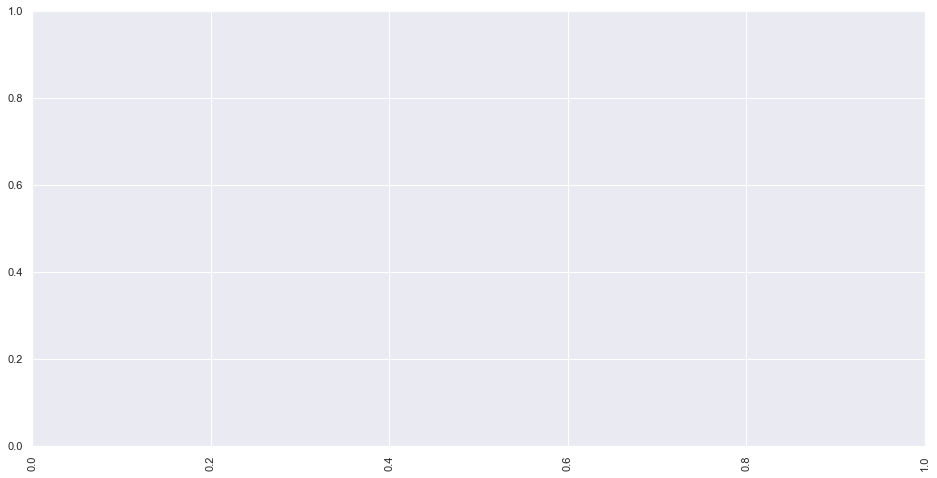

In [11]:
# average hits overlap by functional class
sns.set(rc={"figure.figsize":(16, 8), "axes.labelsize":16})
plt.xticks(rotation=90)
sns.boxplot(x='initial.go', y='avg_hits_overlap', data=df_annot)

<AxesSubplot:xlabel='initial.go', ylabel='avg_hits_overlap'>

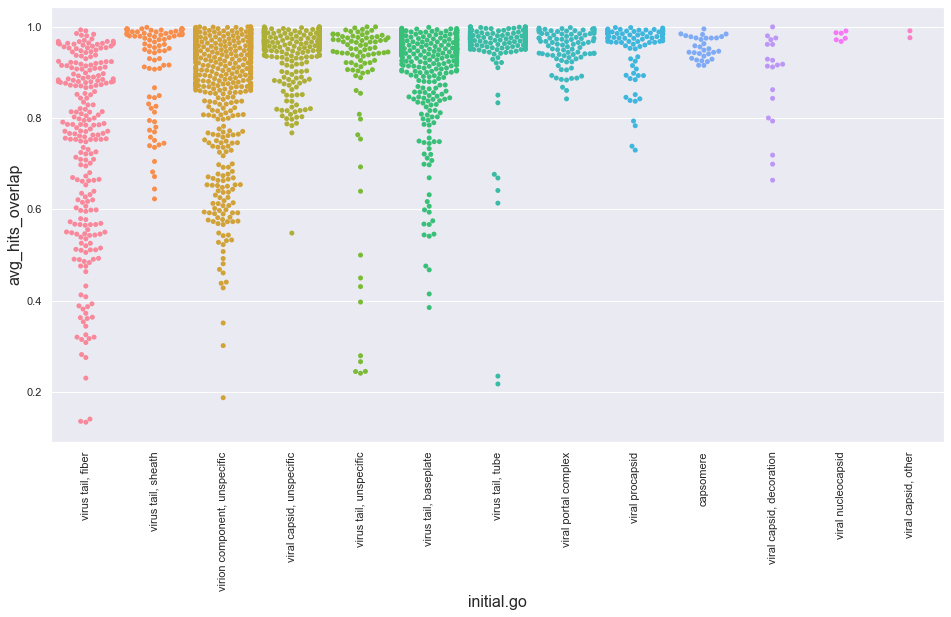

In [170]:
plt.xticks(rotation=90)
sns.swarmplot(x='initial.go', y='avg_hits_overlap', data=df_annot)

<AxesSubplot:xlabel='initial.go', ylabel='count'>

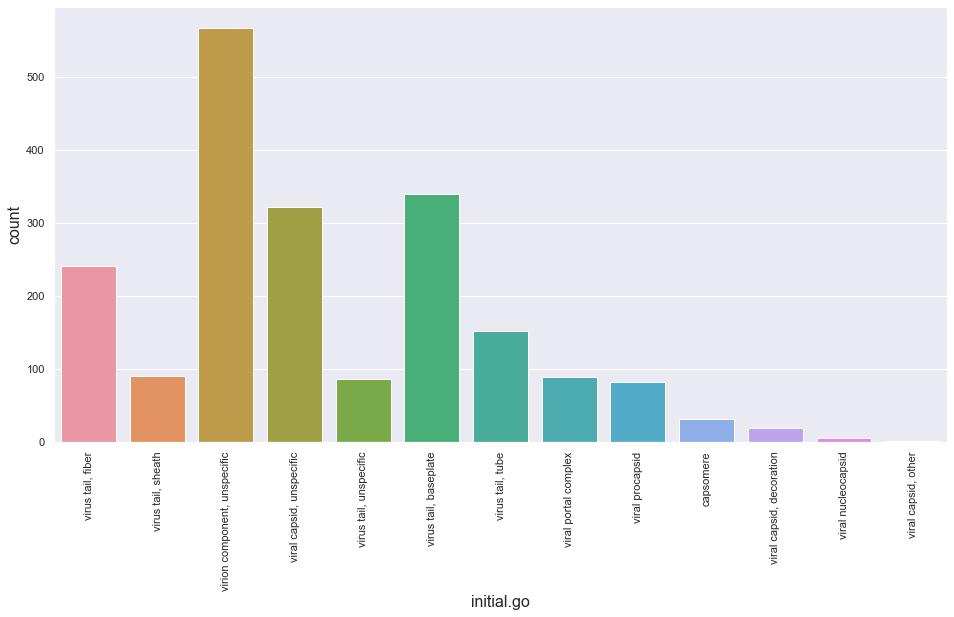

In [160]:
plt.xticks(rotation=90)
sns.countplot(x='initial.go', data=df_annot)

<AxesSubplot:xlabel='initial.go', ylabel='nb_cluster'>

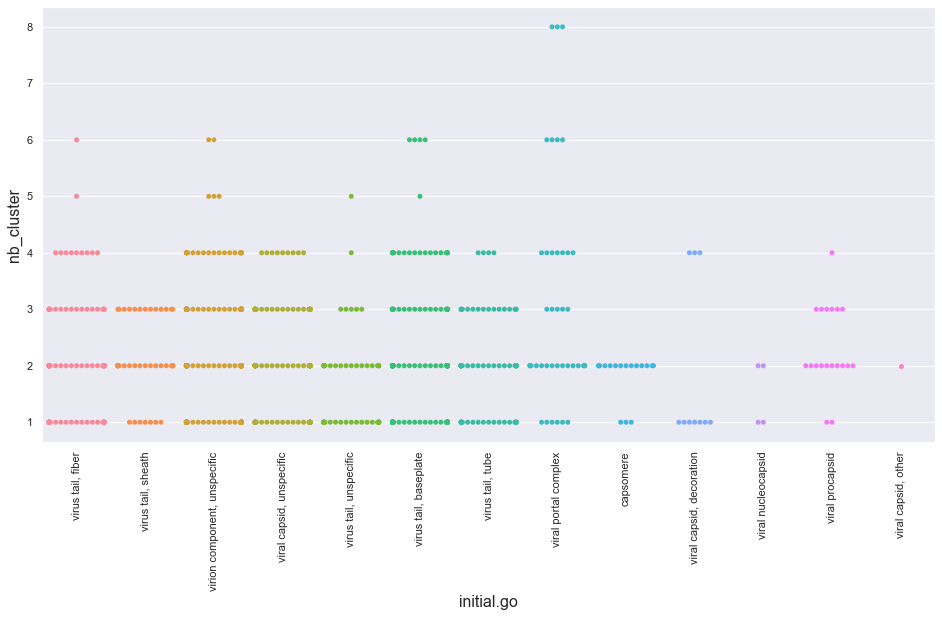

In [171]:
# plot number of clusters (=qECFs)
df_nclust = pd.DataFrame(df_annot.groupby('qname')['cluster'].apply(lambda x: len(x)))
df_nclust.rename(columns = {'cluster':'nb_cluster'}, inplace=True)
df_nclust_nr = df_annot.join(df_nclust, on='qname')
df_nclust_nr.drop_duplicates('qname', inplace=True)
plt.xticks(rotation=90)
# sns.boxplot(x='initial.go', y='nb_cluster', data=df_nclust_nr)
sns.swarmplot(x='initial.go', y='nb_cluster', data=df_nclust_nr)

In [164]:
### additional plots that were created in previous version (implement as needed):
# count qECF/prot - this done with qECF / prot by function [maybe do all plots this way?]
# qECF span by funct
# qECF avg-hit-len to qECF span by funct
# qECF nb_hits to funct
df_annot.head()

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength,initial.go,cov
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000,NaN,NaN
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986,NaN,NaN
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926,NaN,NaN
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294,NaN,NaN
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711,NaN,NaN


<AxesSubplot:xlabel='initial.go', ylabel='avg_hit_len_to_ecf_span'>

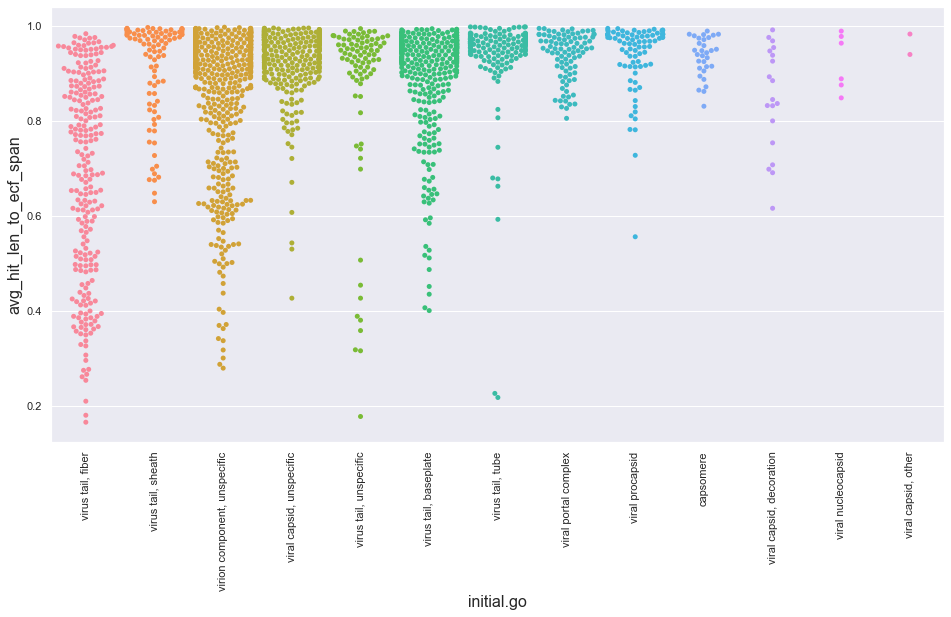

In [175]:
plt.xticks(rotation=90)
sns.swarmplot(x='initial.go', y='avg_hit_len_to_ecf_span', data=df_annot)

In [210]:
# load hhrepid data
features_to_load = ['hhrepid']

hhrepid_data = load_features_data(workdir_path, features_to_load, sep=',')
for fname, fdata in hhrepid_data.items():
    print(fname)
    display(fdata)

hhrepid


,qname,annot,type-pval,type-len,rep-id,prob,pval,rep-score,rep-score-norm,qstart,qend,sstart,send,rep-len,rep-offset,rep-seq
0,reprseq23453,A,3.700000e-30,104,A1,0.0,7.900000e-01,6.69,0.09,335,420,555,634,80,35,-AIDKIRKLLSIGFNQ.Aty.IVETKLYQLS..K..MSVQDLKdeI...
1,reprseq23453,A,3.700000e-30,104,A2,0.0,4.200000e-21,65.11,0.70,456,553,557,653,93,0,---NAYVFAKSTDEII.SgdtRGRKGQNFVP..S..TVKKVII..E...
2,reprseq23453,A,3.700000e-30,104,A3,0.0,9.900000e-30,74.36,0.71,554,657,554,657,104,0,VTEAGYMKRIPVDGFD.L...NRKAAVIAIK..P..TEGDILK..A...
3,reprseq23453,A,3.700000e-30,104,A4,0.0,8.000000e-23,68.60,0.82,658,746,558,642,84,0,----GKGKIIDLEEFPlR...RGDKGRRSMLkaItlAEGEMLI..G...
4,reprseq36738,A,5.600000e-11,66,A1,0.0,3.700000e-17,38.94,0.68,26,82,26,82,57,3,--DTQAATVLHAAVGIAGEVAELLVAS..........SIENLVEEM...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9309,reprseq12697,C,1.300000e-11,7,C3,0.0,3.500000e-05,1.82,0.26,172,178,186,192,7,7,TIKTQTSqlkadtq
9310,reprseq12697,C,1.300000e-11,7,C4,0.0,3.300000e-05,1.55,0.22,186,192,186,192,7,7,AIKDQTNqiktdtg
9311,reprseq12697,C,1.300000e-11,7,C5,0.0,9.500000e-06,1.84,0.26,200,206,186,192,7,0,VIRDEAN.......
9312,reprseq12697,C,1.300000e-11,7,C6,0.0,2.200000e-05,1.72,0.25,207,213,186,192,7,0,TAKEDAQ.......


In [211]:
hhrepid_data = hhrepid_data['hhrepid'].assign(repeat = True)
hhrepid_data_repeat = hhrepid_data[['qname', 'repeat']]
hhrepid_data_repeat.drop_duplicates(inplace=True)
hhrepid_data_repeat

,qname,repeat
0,reprseq23453,True
4,reprseq36738,True
6,reprseq20628,True
14,reprseq19081,True
21,reprseq36076,True
...,...,...
9285,reprseq25991,True
9292,reprseq24443,True
9294,reprseq26254,True
9296,reprseq10080,True


In [212]:
df_annot_repeat = df_annot.join(hhrepid_data_repeat.set_index('qname'), on='qname')
df_annot_repeat

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength,initial.go,cov,repeat
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000,NaN,NaN,NaN
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986,NaN,NaN,True
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926,NaN,NaN,True
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294,NaN,NaN,True
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711,NaN,NaN,True
...,...,...,...,...,...,...,...,...,...,...
21816,reprseq28150,0,6,0.987179,246,0.981707,0.987952,NaN,NaN,NaN
21817,reprseq28150,1,5,0.980762,230,0.974783,0.923695,NaN,NaN,NaN
21818,reprseq17482,0,54,0.930663,194,0.846793,0.989796,NaN,NaN,NaN
21819,reprseq17482,1,19,0.861693,109,0.783679,0.556122,NaN,NaN,NaN


In [213]:
df_annot_repeat['repeat'].fillna(False, inplace=True)

In [214]:
df_annot_repeat

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength,initial.go,cov,repeat
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000,NaN,NaN,False
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986,NaN,NaN,True
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926,NaN,NaN,True
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294,NaN,NaN,True
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711,NaN,NaN,True
...,...,...,...,...,...,...,...,...,...,...
21816,reprseq28150,0,6,0.987179,246,0.981707,0.987952,NaN,NaN,False
21817,reprseq28150,1,5,0.980762,230,0.974783,0.923695,NaN,NaN,False
21818,reprseq17482,0,54,0.930663,194,0.846793,0.989796,NaN,NaN,False
21819,reprseq17482,1,19,0.861693,109,0.783679,0.556122,NaN,NaN,False


<AxesSubplot:xlabel='initial.go', ylabel='avg_hits_overlap'>

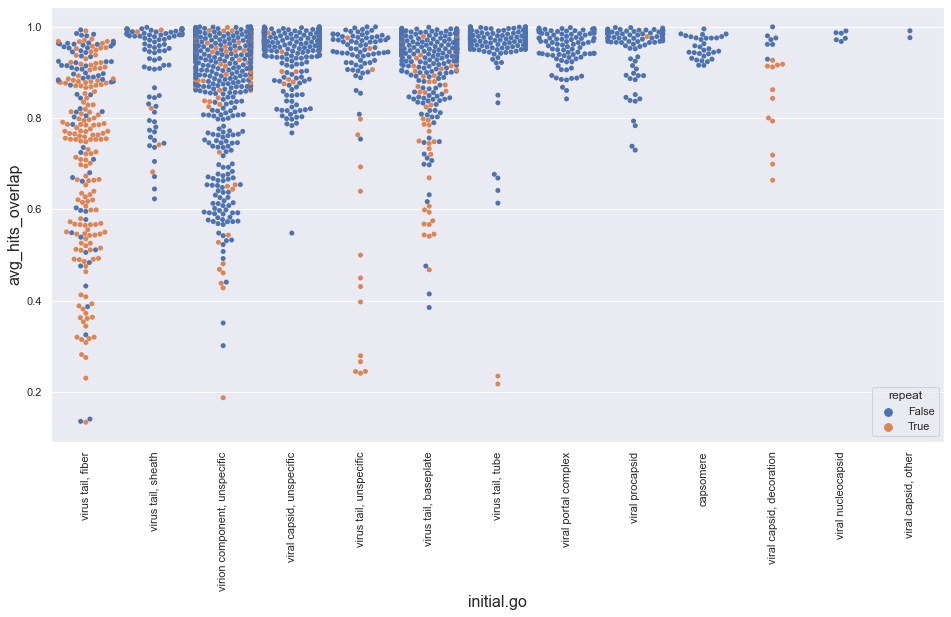

In [215]:
plt.xticks(rotation=90)
sns.swarmplot(x='initial.go', y='avg_hits_overlap', data=df_annot_repeat, hue='repeat')

In [182]:
clustering_results

,qname,cluster,nb_hits,avg_hits_overlap,ecf_span,avg_hit_len_to_ecf_span,span_to_qlength
0,reprseq28520,0,21,0.949422,56,0.892007,0.700000
1,reprseq10133,0,8,0.916683,395,0.888924,0.569986
2,reprseq10133,1,5,0.975040,282,0.979433,0.406926
3,reprseq10133,2,47,0.642516,258,0.470559,0.372294
4,reprseq10133,3,5,0.918589,277,0.916968,0.399711
...,...,...,...,...,...,...,...
21816,reprseq28150,0,6,0.987179,246,0.981707,0.987952
21817,reprseq28150,1,5,0.980762,230,0.974783,0.923695
21818,reprseq17482,0,54,0.930663,194,0.846793,0.989796
21819,reprseq17482,1,19,0.861693,109,0.783679,0.556122


In [183]:
# add ecf_span_start & ecf_span_end to clustering results 
# (requires recalculating clusters and stats - maybe do this along with masking hits by hhrepid)
# create dict that maps reprseq with (ecf_span_start, ecf_span_end)
# to each row in clustering_results apply function that checks whether qECF span overlaps with any repeat position
# resulting clustering_results table has a new column repeat of value True/False
# then plot AHO with hue of repeat